# RHIS — USGS-01646500 

In [ ]:
%pip install dataretrieval # USGS package for data retrieval
%pip install geopandas
%pip install --index-url https://test.pypi.org/simple/ --extra-index-url https://pypi.org/simple/ rhis-ts==0.1.0

In [1]:
from rhis_ts import Rhis
from dataretrieval import waterdata
from helpers import build_rhis_evol_df, build_repr_df
from plotting import plot_rhis_evolution # Helper function to plot the representative series along with their p-value evolutions

In [2]:
# Get daily streamflow data (returns DataFrame and metadata)
df, metadata = waterdata.get_daily(
    monitoring_location_id="USGS-01646500",
    parameter_code="00060",  # Discharge
    time="1925-01-01/2025-01-01",
)

print(f"Retrieved {len(df)} records")
print(f"Site: {df['monitoring_location_id'].iloc[0]}")
print(f"Mean discharge: {df['value'].mean():.2f} {df['unit_of_measure'].iloc[0]}")

df.info()

Retrieving: daily · 1 page · 34,641 rows


Retrieved 34641 records
Site: USGS-01646500
Mean discharge: 11410.02 ft^3/s
<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 34641 entries, 0 to 34640
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype              
---  ------                  --------------  -----              
 0   geometry                34641 non-null  geometry           
 1   time_series_id          34641 non-null  str                
 2   monitoring_location_id  34641 non-null  str                
 3   parameter_code          34641 non-null  str                
 4   statistic_id            34641 non-null  str                
 5   time                    34641 non-null  datetime64[us]     
 6   value                   34641 non-null  float64            
 7   unit_of_measure         34641 non-null  str                
 8   approval_status         34641 non-null  str                
 9   qualifier               298 non-null    object             
 10  last_modified         

<Axes: title={'center': 'Daily streamflow — USGS-01646500'}, xlabel='time', ylabel='discharge (ft^3/s)'>

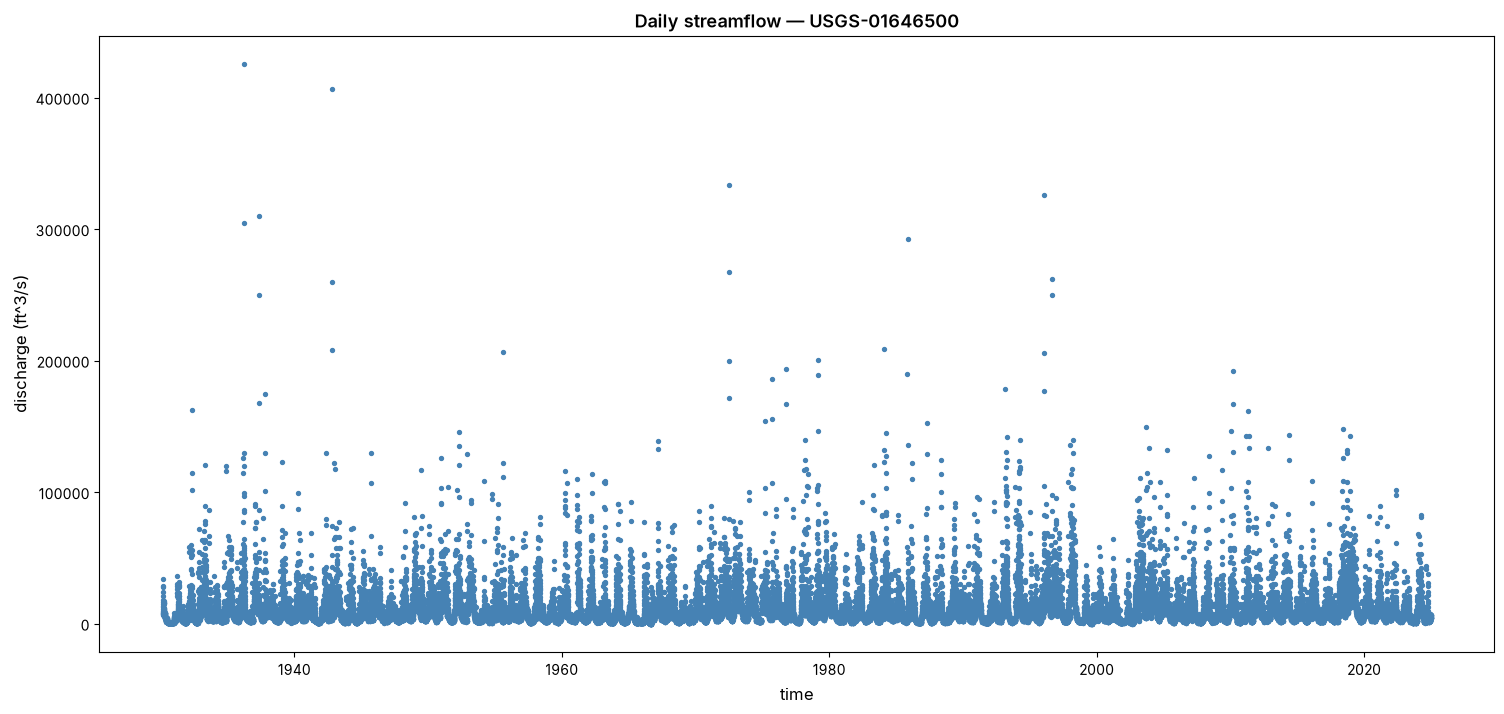

In [6]:
df.plot(
    x="time", y="value", kind="scatter", s=8, color="steelblue",
    figsize=(18, 8),
    title="Daily streamflow — USGS-01646500",
    xlabel="time", ylabel="discharge (ft^3/s)",
)

In [7]:
df = df.set_index('time') # Set time as the dataframe index, so Rhis doesn't treat it as data to be analyzed
df = df[['value']]

## Getting the indexes that give the representative slice

In [8]:
rhis = Rhis(df)
repr_idxs = rhis.get_repr_idxs() # Get the indexes that define the most recent RHIS-compliant stretch. It doesn't save the p-values

print(repr_idxs)

{'value': (34632, 34641)}


The method returned (3645, 3654), which means that the longest most recent slice that is RHIS compliant is the slice with the last 9 values of flows.

## p-value evolutions

In [9]:
p_evol = rhis.build_rhis_evol_dict() # Save the p-value evolutions
rhis_df = build_rhis_evol_df(rhis) # This is just a helper function to create a datafarme from the p-value evolutions
repr_df = build_repr_df(rhis) # This is just a helper function to create a datafarme from with the representative stretches from each time series

<Axes: title={'center': 'RHIS-compliant Daily streamflow — USGS-01646500'}, xlabel='time', ylabel='discharge (ft^3/s)'>

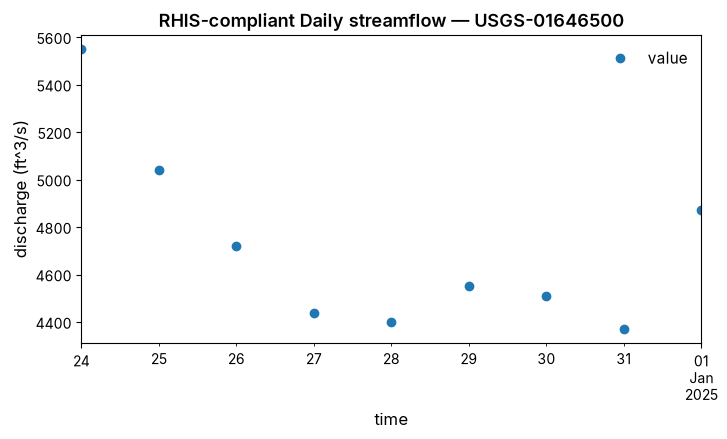

In [10]:
start, stop = repr_idxs["value"]
repr_df.iloc[start:stop].plot(
    kind="line", figsize=(8, 4),
    style="o",
    linestyle="None",
    title="RHIS-compliant Daily streamflow — USGS-01646500",
    xlabel="time", ylabel="discharge (ft^3/s)",
)

We cannot say that these last 9 values aren't under influence of some variability pattern, but only that these 9 values don't provide enough evidence to reject any of the RHIS hypotheses. The plot clearly shows the dependence between daily flows.

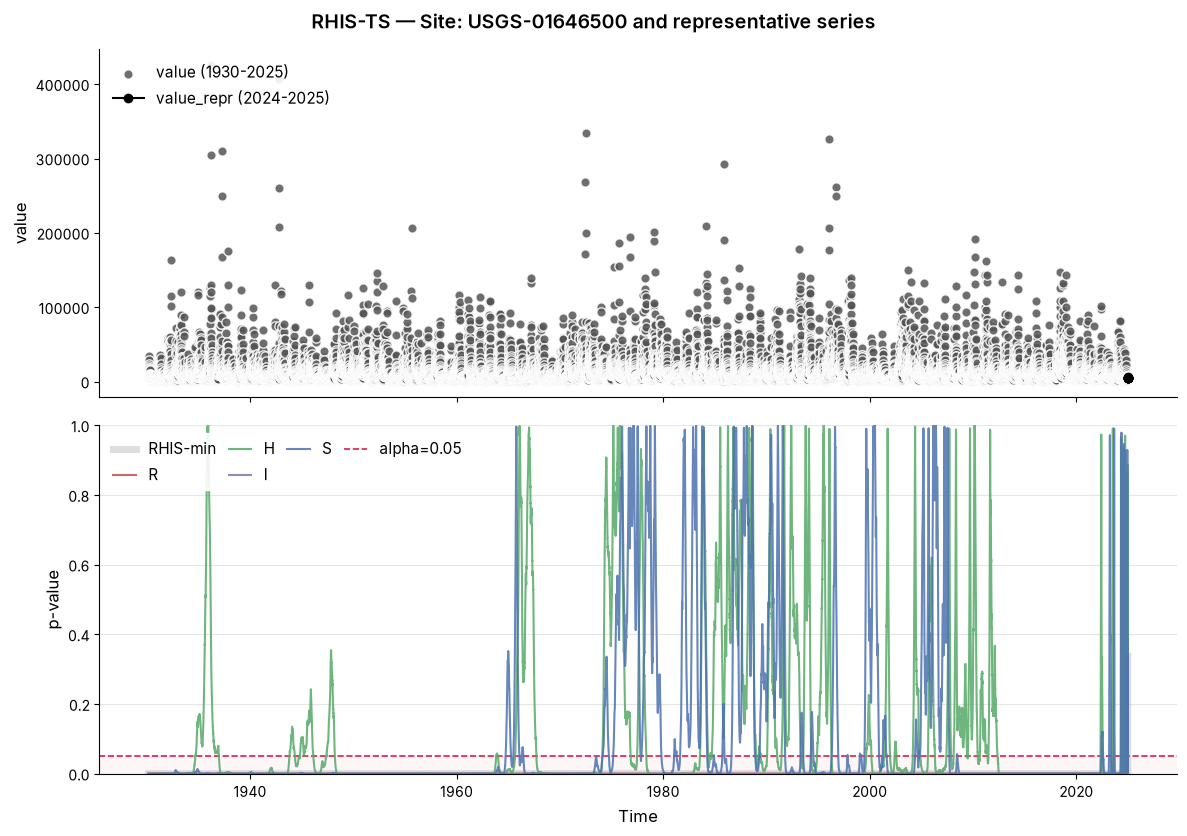

In [12]:
plot_rhis_evolution(
    rhis.numeric_orig_df,
    rhis_df, 0.05,
    show_repr=True,
    save=False,
    repr_df=repr_df,
    figtitle='RHIS-TS — Site: USGS-01646500 and representative series',
    savename='USGS-01646500',
    figsize=(12, 8.5)
    )

The p-values start all below alpha level and continue until the beginning of 2022, which means that no slice starting before this time is RHIS-compliant — their are unable to provide reliable statistics. Going towards the most recent, although homogeneity and stationarity move above the rejection level, randomness and independence continue being rejected until 2024-12-24, when hypotheses could not be rejected.

## Looking closer (last 100 elements)

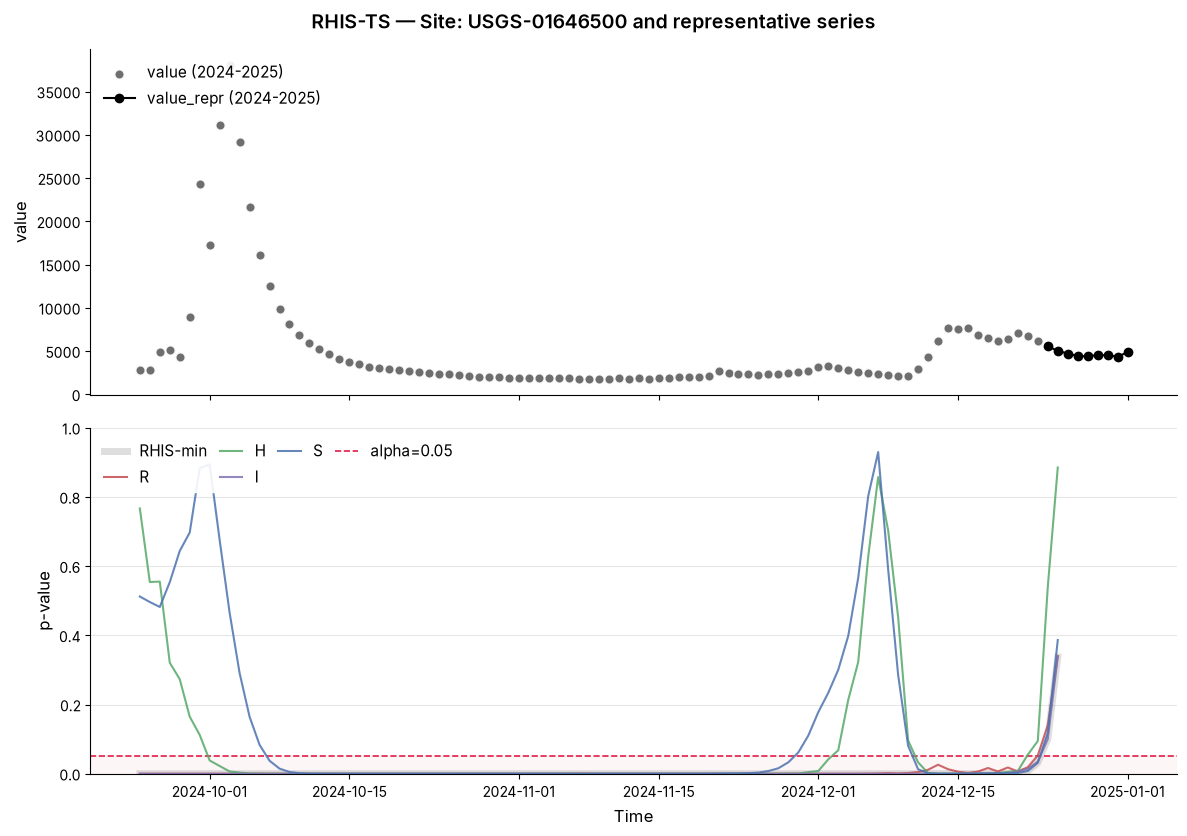

In [13]:
back_incr = 91
plot_rhis_evolution(
    rhis.numeric_orig_df.iloc[start - back_incr:stop],
    rhis_df.iloc[start - back_incr:stop], 0.05,
    show_repr=True,
    save=False,
    repr_df=repr_df.iloc[start - back_incr:stop],
    figtitle='RHIS-TS — Site: USGS-01646500 and representative series',
    savename='USGS-01646500',
    figsize=(12, 8.5)
    )

Here we can see that the last p-values are the ones from the last 8 values, which is the minimum length for the tests — randomness, independence, and stationarity are between 0.35—0.40, and homogeneity around 0.9. Moving backwards one time step, the time series has 9 values and it's the last time that all RHIS hypotheses are not rejected. Moving backwards from this point, randomness get rejected forever. That's why the longest most recent RHIS-compliant stretch are the last 9 values.

# What about monthly scale?

We can expect less dependence between flows, but seasonality will still be present and should continue to cause several rejection of randomness.

In [14]:
df_monthly = df.resample("MS").mean().reset_index().set_index('time')

<Axes: title={'center': 'Monthly streamflow — USGS-01646500'}, xlabel='time', ylabel='discharge (ft^3/s)'>

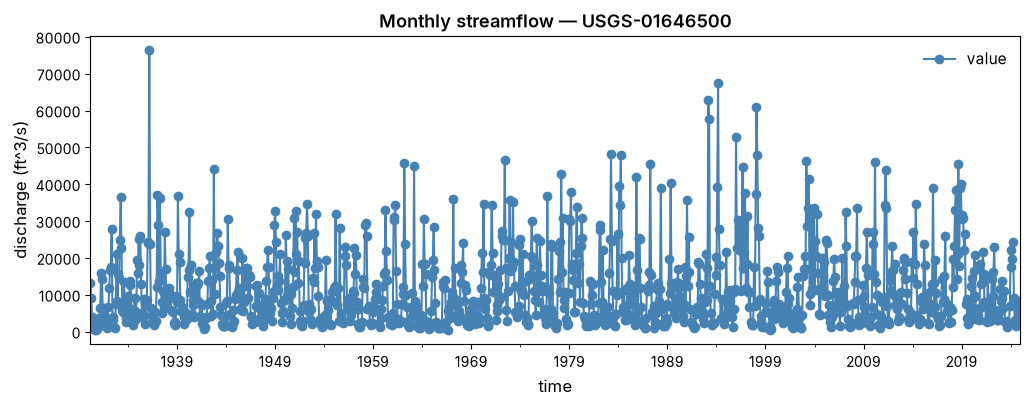

In [15]:
df_monthly.plot(
    kind="line", style='o', linestyle=None, color="steelblue",
    figsize=(12, 4),
    title="Monthly streamflow — USGS-01646500",
    xlabel="time", ylabel="discharge (ft^3/s)",
)

{'value': (1127, 1139)}


<Axes: title={'center': 'RHIS-compliant Monthly streamflow — USGS-01646500'}, xlabel='time', ylabel='discharge (ft^3/s)'>

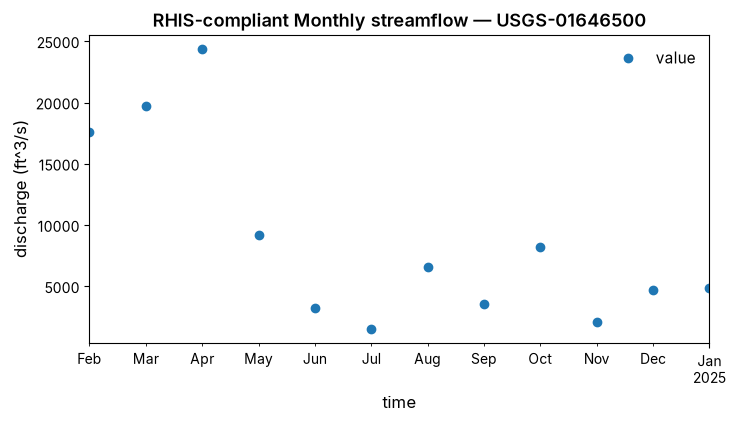

In [16]:
rhis_m = Rhis(df_monthly)
repr_idxs_m = rhis_m.get_repr_idxs() # Get the indexes that define the most recent RHIS-compliant stretch. It doesn't save the p-values
print(repr_idxs_m)

p_evol = rhis_m.build_rhis_evol_dict() # Save the p-value evolutions
rhis_df_m = build_rhis_evol_df(rhis_m) # This is just a helper function to create a datafarme from the p-value evolutions
repr_df_m = build_repr_df(rhis_m) # This is just a helper function to create a datafarme from with the representative stretches from each time series

start, stop = repr_idxs_m["value"]
repr_df_m.iloc[start:stop].plot(
    kind="line", figsize=(8, 4),
    style="o",
    linestyle="None",
    title="RHIS-compliant Monthly streamflow — USGS-01646500",
    xlabel="time", ylabel="discharge (ft^3/s)",
)


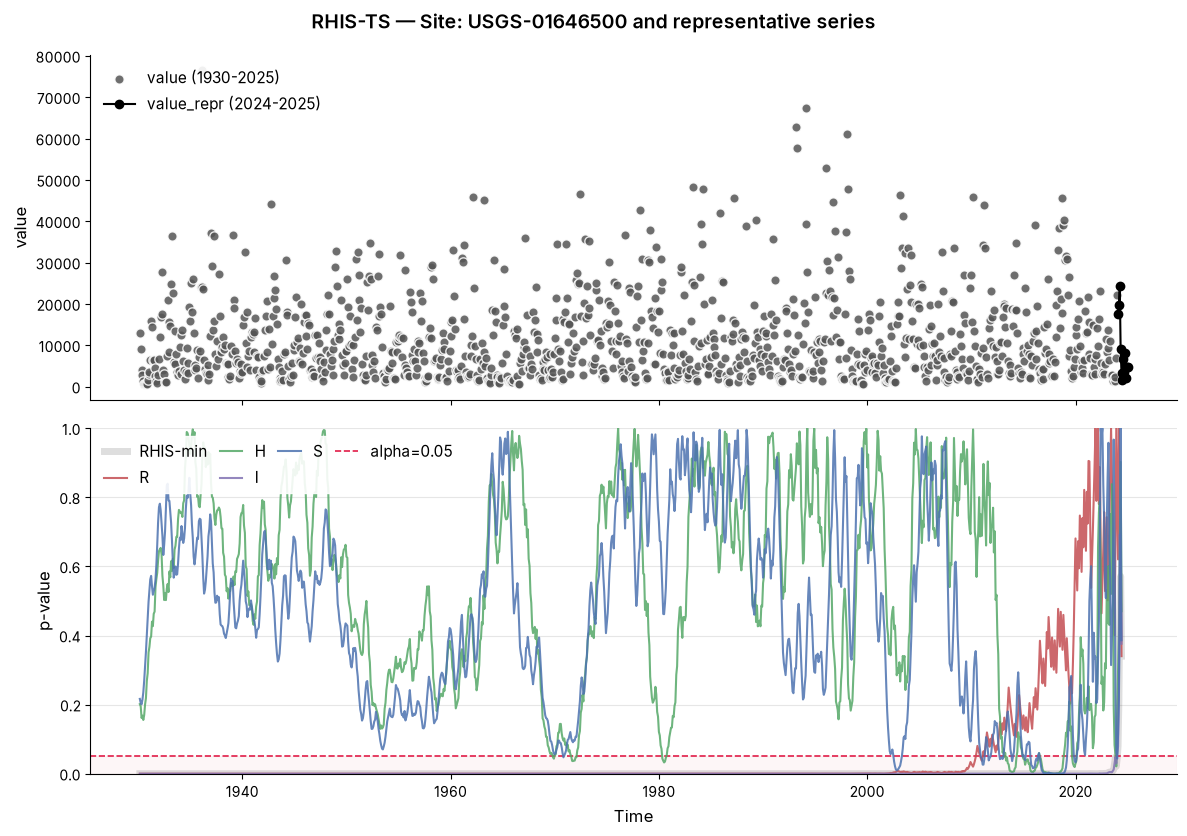

In [17]:
plot_rhis_evolution(
    rhis_m.numeric_orig_df,
    rhis_df_m, 0.05,
    show_repr=True,
    save=False,
    repr_df=repr_df_m,
    figtitle='RHIS-TS — Site: USGS-01646500 and representative series',
    savename='USGS-01646500',
    figsize=(12, 8.5)
    )

Seasonality still has significant impact on dependence even on monthly scale.

## And annual flows?

<Axes: title={'center': 'Annual streamflow — USGS-01646500'}, xlabel='time', ylabel='discharge (ft^3/s)'>

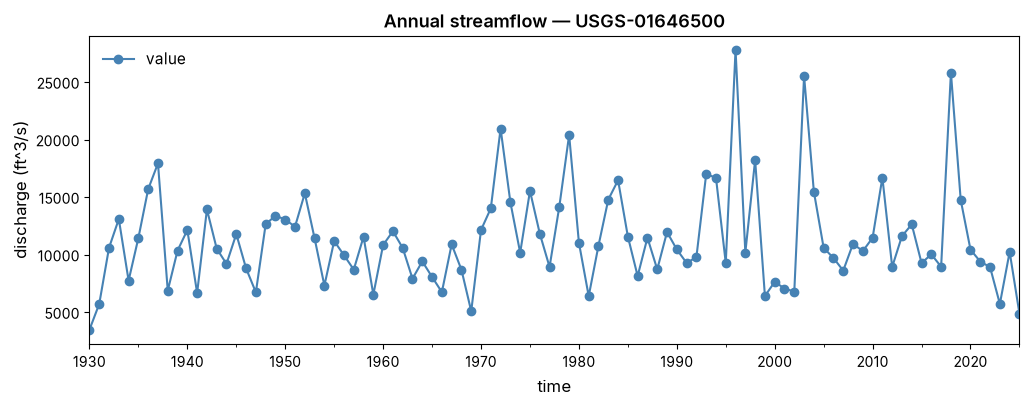

In [18]:
df_annual = df.resample("YS").mean().reset_index().set_index('time')

df_annual.plot(
    kind="line", style='o', linestyle=None, color="steelblue",
    figsize=(12, 4),
    title="Annual streamflow — USGS-01646500",
    xlabel="time", ylabel="discharge (ft^3/s)",
)

{'value': (0, 96)}


<Axes: title={'center': 'RHIS-compliant Monthly streamflow — USGS-01646500'}, xlabel='time', ylabel='discharge (ft^3/s)'>

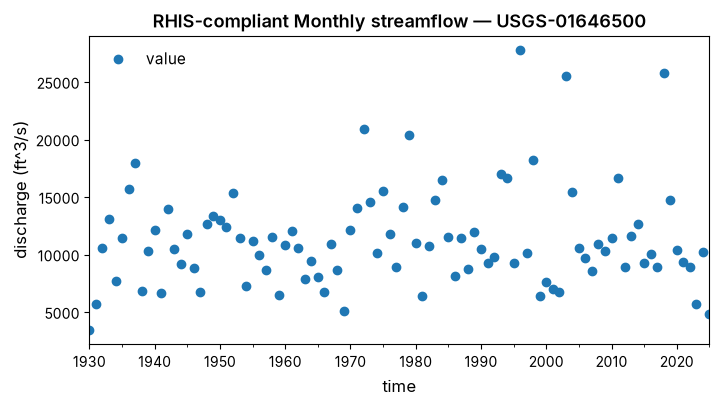

In [19]:
rhis_y = Rhis(df_annual)
repr_idxs_y = rhis_y.get_repr_idxs() # Get the indexes that define the most recent RHIS-compliant stretch. It doesn't save the p-values
print(repr_idxs_y)

p_evol = rhis_y.build_rhis_evol_dict() # Save the p-value evolutions
rhis_df_y = build_rhis_evol_df(rhis_y) # This is just a helper function to create a datafarme from the p-value evolutions
repr_df_y = build_repr_df(rhis_y) # This is just a helper function to create a datafarme from with the representative stretches from each time series

start, stop = repr_idxs_y["value"]
repr_df_y.iloc[start:stop].plot(
    kind="line", figsize=(8, 4),
    style="o",
    linestyle="None",
    title="RHIS-compliant Monthly streamflow — USGS-01646500",
    xlabel="time", ylabel="discharge (ft^3/s)",
)

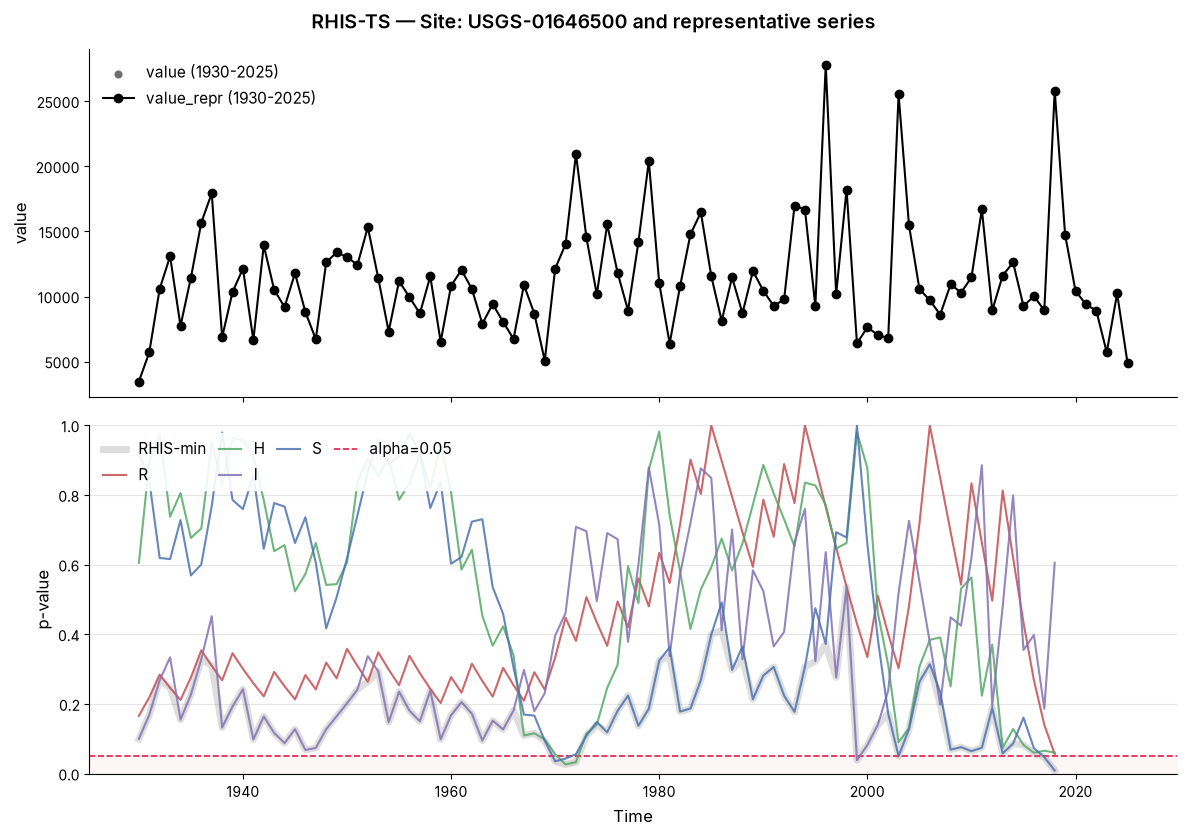

In [20]:
plot_rhis_evolution(
    rhis_y.numeric_orig_df,
    rhis_df_y, 0.05,
    show_repr=True,
    save=False,
    repr_df=repr_df_y,
    figtitle='RHIS-TS — Site: USGS-01646500 and representative series',
    savename='USGS-01646500',
    figsize=(12, 8.5)
    )